# 5. Light-Sheet smFRET Camera Simulation

This notebook simulates **camera frames of fluorescence emission** from freely diffusing particles, as observed with a light-sheet microscope. It takes the particle-diffusion machinery of `1_Trajectory_Simulation.ipynb` and replaces the confocal PSF + TCSPC-timestamp detection with a **light-sheet PSF + camera**.

The light-sheet PSF is computed with the [`psfmodels`](https://github.com/scottptt/psfmodels) module and wrapped in the class `LightSheetPSF` (`lightsheet_psf.py`), which implements the pybromo PSF interface (`eval`, `eval_xz`, `hash`, `to_hdf5`).

The physical model is deliberately simple:

1. **Excitation**: a Gaussian light sheet, thin in $z$ and uniform in $x/y$. For a sheet formed by a low-NA Gaussian beam, the 1/e² intensity waist is $w_0 = \lambda_{ex} / (\pi\,\mathrm{NA}_{sheet})$, so the excitation intensity at particle height $z$ is

$$I_{exc}(z) = \exp\left(-2\,(z/w_0)^2\right).$$

2. **Detection**: the vectorial widefield PSF of the detection objective (Gibson–Lanni model, `psfmodels.make_psf`), evaluated on a $z$ stack so that particles away from the focal plane form **broadened, dimmer** camera spots, with the photon number conserved per $z$ plane.

3. **Effective PSF**: the product $I_{exc}(z) \cdot PSF_{det}(x, y, z)$, precomputed on a 3D grid and linearly interpolated (`eval`).

4. **Camera frames**: for each 50 ms frame, the expected photon counts of each particle (modulated by the sheet profile at its $z$ position) are binned on the camera pixel grid per $z$ plane, convolved with the sum-normalized detection kernel at that defocus, and Poisson-sampled into integer pixel counts.

In [1]:
%matplotlib inline
import numpy as np
import tables
import matplotlib.pyplot as plt
import pybromo as pbm
import psfmodels
from lightsheet_psf import LightSheetPSF

print('Numpy version:', np.__version__)
print('PyTables version:', tables.__version__)
print('PyBroMo version:', pbm.__version__)
print('psfmodels version:', psfmodels.__version__)

/workspace/github__Tomkaehst__PyBroMo/pybromo/psflib.py:15: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Numpy version: 2.5.4
PyTables version: 3.11.1
PyBroMo version: 0+untagged.1.g5fecc87
psfmodels version: 0.3.3


## 1. The light-sheet PSF

`LightSheetPSF` parameters:

| Parameter | Value | Meaning |
|---|---|---|
| `dxy` | 0.2 µm | lateral grid step = camera pixel size (sample space) |
| `nx` | 51 | lateral grid size |
| `dz`, `nz_half` | 0.25 µm, 24 | z grid spanning ±6 µm around focus |
| `det_NA` | 0.8 | detection objective NA |
| `em_wvl` | 0.58 µm | emission wavelength |
| `ex_wvl`, `sheet_NA` | 0.488 µm, 0.08 | light-sheet excitation |

In [2]:
ls_psf = LightSheetPSF(dxy=0.2, nx=51, dz=0.25, nz_half=24,
                        det_NA=0.8, em_wvl=0.58,
                        ex_wvl=0.488, sheet_NA=0.08)
print(ls_psf)
print('Sheet 1/e^2 waist w0: %.2f um' % ls_psf.sheet_waist)
print('PSF volume:', ls_psf.psf_volume.shape)
print('PSF hash:', ls_psf.hash()[:12])

LightSheetPSF(dxy=0.2um, nx=51, dz=0.25um, nz_half=24, det_NA=0.8, em_wvl=0.58um, ex_wvl=0.488um, sheet_NA=0.08)
Sheet 1/e^2 waist w0: 1.94 um
PSF volume: (49, 51, 51)
PSF hash: 7f0b4690d306


## 2. Validation of the physical model

Before simulating camera data, the PSF is checked against the analytical expectations:

- **Lateral width**: the diffraction-limited detection PSF has an Airy-profile FWHM $\approx 0.51\,\lambda/\mathrm{NA}$ (fine 0.05 µm grid to avoid pixel-size bias)
- **Axial extent**: the effective light-sheet PSF must be confined in $z$ by the sheet, not by the detection depth of field
- **Photon conservation**: the sum-normalized detection kernels must conserve photon counts at every defocus
- **Defocus broadening**: the camera spot of a particle must broaden (and dim) away from focus

In [3]:
# --- Validation on a fine lateral grid (0.05 um) to measure true widths ---
ls_fine = LightSheetPSF(dxy=0.05, nx=101, dz=0.25, nz_half=24)

def fwhm(profile, step):
    prof = profile / profile.max()
    idx = np.where(prof >= 0.5)[0]
    return (idx[-1] - idx[0] + 1) * step

# Lateral: in-focus detection PSF vs Airy FWHM 0.51*lam/NA
k0 = ls_fine.detection_kernel(0.0)
lat_fwhm = fwhm(k0[k0.shape[0]//2], ls_fine.dxy)
airy_fwhm = 0.51 * ls_fine.em_wvl / ls_fine.det_NA
print(f"In-focus detection FWHM: {lat_fwhm:.3f} um   (Airy theory: {airy_fwhm:.3f} um)")

# Axial: effective PSF is confined by BOTH the sheet Gaussian and the
# detection depth of field; it must be narrower than either alone
zprof = ls_fine.psf_volume[:, ls_fine.nx//2, ls_fine.nx//2]
ax_fwhm = fwhm(zprof, ls_fine.dz)
det_z = ls_fine.detection_psf[:, ls_fine.nx//2, ls_fine.nx//2]
det_ax_fwhm = fwhm(det_z, ls_fine.dz)
sheet_fwhm = 2 * np.sqrt(2*np.log(2)) * ls_fine.sheet_waist
print(f"Effective axial FWHM:     {ax_fwhm:.3f} um   (detection-only: {det_ax_fwhm:.3f} um, sheet-only: {sheet_fwhm:.3f} um)")
assert ax_fwhm < det_ax_fwhm and ax_fwhm < sheet_fwhm, "effective PSF must be narrower than both factors"
print("  -> narrower than both the detection DOF and the sheet alone, as expected")

# Photon conservation of the rendering: single particle at fixed positions
em_rate, t_step, n = 50e3, 1e-3, 200
print("\nPhoton conservation (particle at x=y=0, fixed z, 200 ms exposure):")
for z_fix in [0.0, 1e-6, 2e-6, 4e-6]:
    x = np.zeros((1, n)); y = np.zeros((1, n)); z = np.full((1, n), z_fix)
    img = ls_psf.render_frame_expected(x, y, z, em_rate=em_rate, t_step=t_step)
    expected = em_rate * t_step * n * ls_psf.excitation_weights(np.array([z_fix]))[0]
    print(f"  z = {z_fix*1e6:+.0f} um: expected {expected:8.1f} photons, rendered {img.sum():8.1f}")

# Defocus broadening of the camera spot
print("\nDefocus broadening (camera spot FWHM at 0.2 um pixels):")
for z_fix in [0.0, 1e-6, 2e-6]:
    z = np.full((1, n), z_fix)
    img = ls_psf.render_frame_expected(x, y, z, em_rate=em_rate, t_step=t_step)
    row = img[img.shape[0]//2]
    print(f"  z = {z_fix*1e6:+.0f} um: spot FWHM = {fwhm(row, 0.2):.2f} um, peak = {img.max():.0f} counts/px")

In-focus detection FWHM: 0.350 um   (Airy theory: 0.370 um)
Effective axial FWHM:     1.250 um   (detection-only: 1.750 um, sheet-only: 4.572 um)
  -> narrower than both the detection DOF and the sheet alone, as expected

Photon conservation (particle at x=y=0, fixed z, 200 ms exposure):
  z = +0 um: expected  10000.0 photons, rendered  10000.0
  z = +1 um: expected   5883.2 photons, rendered   5883.2
  z = +2 um: expected   1198.0 photons, rendered   1198.0
  z = +4 um: expected      2.1 photons, rendered      2.1

Defocus broadening (camera spot FWHM at 0.2 um pixels):
  z = +0 um: spot FWHM = 0.60 um, peak = 1939 counts/px
  z = +1 um: spot FWHM = 0.60 um, peak = 546 counts/px
  z = +2 um: spot FWHM = 1.80 um, peak = 16 counts/px


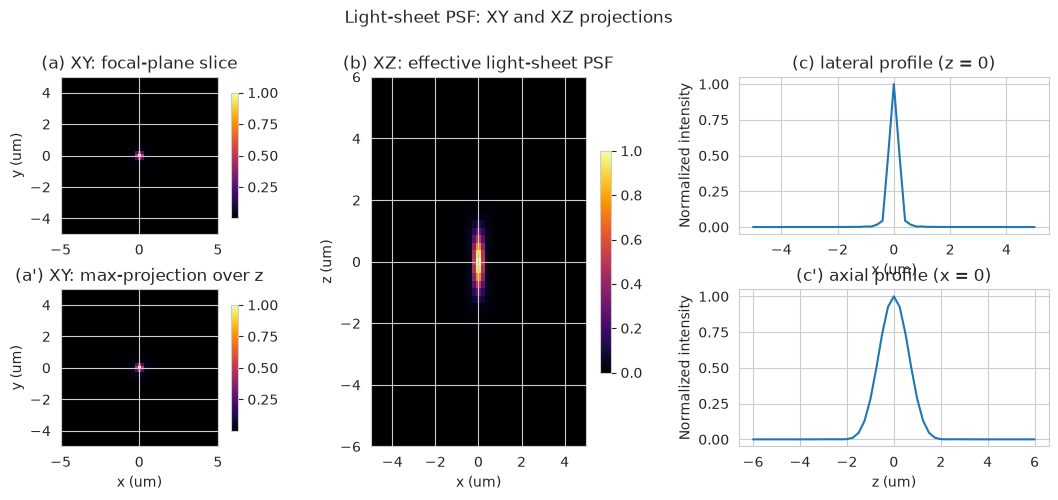

In [4]:
import os
os.makedirs('lightsheet_sim_plots', exist_ok=True)

# Refined PSF figure: XY (focal plane) and XZ projections of the effective PSF
fig = plt.figure(figsize=(13.5, 4.8))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.15], hspace=0.35, wspace=0.35)

# (a) XY projection (max over z) and focal-plane XY slice
c = ls_psf.nx // 2
xy_proj = ls_psf.psf_volume.max(axis=0)          # projection through the sheet (what the camera integrates)
ext_xy = [ls_psf.x_um[0], ls_psf.x_um[-1], ls_psf.y_um[0], ls_psf.y_um[-1]]

ax_a = fig.add_subplot(gs[0, 0]); ax_a.set_title('(a) XY: focal-plane slice')
im_a = ax_a.imshow(ls_psf.psf_volume[ls_psf.nz_half], extent=ext_xy, origin='lower', cmap='inferno')
ax_a.set_ylabel('y (um)'); plt.colorbar(im_a, ax=ax_a, shrink=0.8)

ax_b = fig.add_subplot(gs[1, 0]); ax_b.set_title('(a\') XY: max-projection over z')
im_b = ax_b.imshow(xy_proj, extent=ext_xy, origin='lower', cmap='inferno')
ax_b.set_xlabel('x (um)'); ax_b.set_ylabel('y (um)'); plt.colorbar(im_b, ax=ax_b, shrink=0.8)

# (b) XZ projection (max over y) of the effective PSF, plus line profiles
xz_proj = ls_psf.psf_volume[:, c, :]              # XZ plane at y = 0
ext_xz = [ls_psf.x_um[0], ls_psf.x_um[-1], ls_psf.z_um[0], ls_psf.z_um[-1]]
ax_c = fig.add_subplot(gs[:, 1]); ax_c.set_title('(b) XZ: effective light-sheet PSF')
im_c = ax_c.imshow(xz_proj, extent=ext_xz, origin='lower', cmap='inferno', aspect='auto')
ax_c.set_xlabel('x (um)'); ax_c.set_ylabel('z (um)')
plt.colorbar(im_c, ax=ax_c, shrink=0.6)

# (c) line profiles through the XZ projection
ax_d = fig.add_subplot(gs[0, 2]); ax_d.set_title('(c) lateral profile (z = 0)')
ax_d.plot(ls_psf.x_um, xz_proj[ls_psf.nz_half] / xz_proj[ls_psf.nz_half].max())
ax_d.set_xlabel('x (um)'); ax_d.set_ylabel('Normalized intensity')

ax_e = fig.add_subplot(gs[1, 2]); ax_e.set_title('(c\') axial profile (x = 0)')
ax_e.plot(ls_psf.z_um, xz_proj[:, c] / xz_proj[:, c].max())
ax_e.set_xlabel('z (um)'); ax_e.set_ylabel('Normalized intensity')
fig.suptitle('Light-sheet PSF: XY and XZ projections', y=1.02)
plt.savefig('lightsheet_sim_plots/fig1_psf_xy_xz_projections.png', dpi=150, bbox_inches='tight');

## 3. Effect of a higher-viscosity sample: 20 % glycerol

Adding 20 % glycerol changes two things:

1. **Viscosity**: the viscosity rises from ~1.0 to ~1.8 mPa·s, so by the Stokes–Einstein relation the diffusion coefficient drops by the same factor: $D_{20\%} \approx D_{water} / 1.8$. For the 10 µm²/s used here this gives ~5.6 µm²/s — and since all diffusion times scale as $1/D$, the **mean observation time per molecule roughly doubles**.

2. **Refractive-index mismatch**: the sample index rises from 1.333 (water) to ~1.359 (20 % glycerol). With a water-immersion objective designed for $n = 1.333$, the interface introduces **spherical aberration**: the detection PSF broadens laterally and axially and becomes axially asymmetric, so single-molecule spots get dimmer and wider.

The cell below recomputes the detection PSF with the glycerol parameters (`psfmodels` Gibson–Lanni: sample and immersion at the actual 1.359, objective design index `ni0` at 1.333) and compares it to the matched case.

In [5]:
# --- 20% glycerol: viscosity + refractive-index mismatch ---
viscosity_ratio = 1.8            # eta(20% glycerol) / eta(water) at ~20 C
D_water = 10.0                   # um^2/s in water (the value used in section 4)
D_glyc = D_water / viscosity_ratio
print(f'Diffusion coefficient: {D_water:.1f} um^2/s (water) -> {D_glyc:.2f} um^2/s (20% glycerol)')
print(f'-> all diffusion times (incl. observation time) scale x{viscosity_ratio:.1f}')

# Refractive-index mismatch: water-immersion objective (design ni0=1.333)
# looking into a 20% glycerol sample (actual ni=ns=1.359)
ls_glyc = LightSheetPSF(dxy=0.05, nx=101, dz=0.25, nz_half=32,
                        det_NA=0.8, em_wvl=0.58, ex_wvl=0.488, sheet_NA=0.08,
                        ns=1.359, ni=1.359, ni0=1.333)
ls_water = LightSheetPSF(dxy=0.05, nx=101, dz=0.25, nz_half=32,
                         det_NA=0.8, em_wvl=0.58, ex_wvl=0.488, sheet_NA=0.08,
                         ns=1.333, ni=1.333, ni0=1.333)

def fwhm_p(profile, step):
    prof = profile / profile.max()
    idx = np.where(prof >= 0.5)[0]
    return (idx[-1] - idx[0] + 1) * step

c = ls_water.nx // 2
for name, p in [('water, matched    ', ls_water), ('20% gly, mismatched', ls_glyc)]:
    k0 = p.detection_kernel(0.0)
    lat = fwhm_p(k0[c], p.dxy)
    axdet = fwhm_p(p.detection_psf[:, c, c], p.dz)
    axeff = fwhm_p(p.psf_volume[:, c, c], p.dz)
    up = p.detection_psf[c+1:c+13, c, c].sum()
    dn = p.detection_psf[c-13:c-1, c, c].sum()
    print(f'{name}: lateral FWHM {lat:.2f} um | detection axial FWHM {axdet:.2f} um | '
          f'effective axial FWHM {axeff:.2f} um | axial asymmetry {up/dn:.2f}')
print('-> the mismatched detection PSF is broader and axially asymmetric (spherical aberration),')
print('   in-focus spot peak drops (Strehl-like ratio):',
      round(float(ls_glyc.detection_psf[ls_glyc.nz_half, c, c] / ls_water.detection_psf[ls_water.nz_half, c, c] * (fwhm_p(ls_water.detection_kernel(0.0)[c], ls_water.dxy)/fwhm_p(ls_glyc.detection_kernel(0.0)[c], ls_glyc.dxy))**2), 3))

Diffusion coefficient: 10.0 um^2/s (water) -> 5.56 um^2/s (20% glycerol)
-> all diffusion times (incl. observation time) scale x1.8
water, matched    : lateral FWHM 0.35 um | detection axial FWHM 1.75 um | effective axial FWHM 1.25 um | axial asymmetry 0.13
20% gly, mismatched: lateral FWHM 0.45 um | detection axial FWHM 2.00 um | effective axial FWHM 1.50 um | axial asymmetry 0.26
-> the mismatched detection PSF is broader and axially asymmetric (spherical aberration),
   in-focus spot peak drops (Strehl-like ratio): 0.44


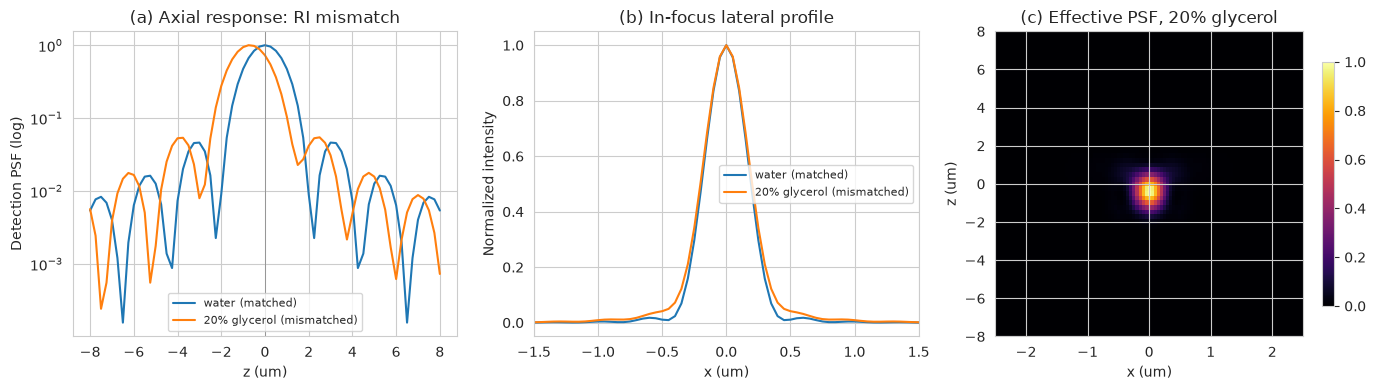

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# (a) axial detection profiles: matched vs mismatched (log y)
c = ls_water.nx // 2
axes[0].semilogy(ls_water.z_um, ls_water.detection_psf[:, c, c], label='water (matched)')
axes[0].semilogy(ls_glyc.z_um, ls_glyc.detection_psf[:, c, c], label='20% glycerol (mismatched)')
axes[0].axvline(0, color='gray', lw=0.5)
axes[0].set_xlabel('z (um)'); axes[0].set_ylabel('Detection PSF (log)')
axes[0].set_title('(a) Axial response: RI mismatch'); axes[0].legend(fontsize=8)

# (b) lateral in-focus profiles
k_w = ls_water.detection_kernel(0.0); k_g = ls_glyc.detection_kernel(0.0)
axes[1].plot(ls_water.x_um, k_w[c] / k_w[c].max(), label='water (matched)')
axes[1].plot(ls_glyc.x_um, k_g[c] / k_g[c].max(), label='20% glycerol (mismatched)')
axes[1].set_xlim(-1.5, 1.5)
axes[1].set_xlabel('x (um)'); axes[1].set_ylabel('Normalized intensity')
axes[1].set_title('(b) In-focus lateral profile'); axes[1].legend(fontsize=8)

# (c) XZ projection of the mismatched effective PSF
xz_g = ls_glyc.psf_volume[:, c, :]
im = axes[2].imshow(xz_g, extent=[ls_glyc.x_um[0], ls_glyc.x_um[-1],
                                  ls_glyc.z_um[0], ls_glyc.z_um[-1]],
                    origin='lower', cmap='inferno', aspect='auto')
axes[2].set_xlabel('x (um)'); axes[2].set_ylabel('z (um)')
axes[2].set_title('(c) Effective PSF, 20% glycerol')
plt.colorbar(im, ax=axes[2], shrink=0.8)
plt.tight_layout()
plt.savefig('lightsheet_sim_plots/fig2_glycerol_effect.png', dpi=150, bbox_inches='tight');

## 4. Particle diffusion simulation (pybromo, camera parameters)

Camera-system simulation parameters:

| Parameter | Value |
|---|---|
| Simulation duration | 100 s |
| Simulation time step | 1 ms |
| Camera frame integration time | 50 ms (50 steps/frame) |
| Diffusion coefficient | 10 µm²/s |
| Particles | 15 |
| Simulation box | 25.6 × 25.6 × 16 µm³ (= 128 × 128 px at 0.2 µm/px) |

In [7]:
rs = np.random.RandomState()
print('Initial random state:', pbm.hashfunc(rs.get_state()))

# Camera system parameters
t_step = 1e-3        # simulation step: 1 ms
t_max = 100          # total simulated time: 100 s
frame_steps = 50     # camera frame integration: 50 steps = 50 ms
frame_time = frame_steps * t_step
pixel_size = 0.2e-6  # camera pixel size in sample space (m)
roi = 128            # camera ROI in pixels

n_frames = int(t_max / frame_time)
print(f'Number of camera frames: {n_frames}')

box = pbm.Box(x1=-roi/2*pixel_size, x2=roi/2*pixel_size,
              y1=-roi/2*pixel_size, y2=roi/2*pixel_size,
              z1=-8e-6, z2=8e-6)

Du = 10.0            # um^2 / s
D1 = Du*(1e-6)**2    # m^2 / s
n_particles = 15
P = pbm.Particles.from_specs(num_particles=(n_particles,), D=(D1,), box=box, rs=rs)

S = pbm.ParticlesSimulation(t_step=t_step, t_max=t_max, particles=P, box=box, psf=ls_psf)
print(S)
S.print_sizes()

Initial random state: 9e46dcf3070fe716235f5d3b2394152c8bdfeed3
Number of camera frames: 2000
Box: X 25.6um, Y 25.6um, Z 16.0um
#Particles: 15 D: 1e-11, 2.4 pM, t_step 1000.0us, t_max 100.0s ID_EID 0 0
  Number of particles: 15
  Number of time steps: 100000
  Emission array - 1 particle (float32): 0.4 MB
  Emission array (float32): 5.7 MB
  Position array (float32): 17.2 MB 


In [8]:
S.simulate_diffusion(
    total_emission=False,
    save_pos=True,
    verbose=True,
    rs=rs,
    chunksize=2**20,
    chunkslice='times'
)

- Start trajectories simulation - Tue Oct 27 22:19:03 2026


[PID 2374] Diffusion time: 1048s


- End trajectories simulation - Tue Oct 27 22:19:04 2026


## 5. Camera frames from the PSF convolution

For each 50 ms frame:

1. **Excitation weighting**: each particle's emission is modulated by the light-sheet profile at its $z$ position — particles outside the sheet go dark
2. **Pixel binning per z plane**: expected photon counts are binned on the 128 × 128 camera grid, grouped by $z$ plane
3. **PSF convolution**: each $z$ slice is convolved with the sum-normalized detection kernel at that defocus — in-focus particles form diffraction-limited spots, defocused ones broad, dim spots
4. **Shot noise**: Poisson sampling yields integer photon counts per pixel (uint16)

Emission rate: 50 kcps per particle at the sheet center; camera background: 10 cps/pixel.

In [9]:
positions = S.position[:]   # (num_particles, 3, n_samples)
print('Positions array:', positions.shape)
print('Samples:', positions.shape[-1], '-> frames:', positions.shape[-1] // frame_steps)

em_rate = 50e3        # photons/s per particle at the sheet center
background_rate = 10  # photons/s/pixel

frames = ls_psf.render_camera_frames(
    positions,
    t_step=t_step,
    frame_steps=frame_steps,
    em_rate=em_rate,
    roi=roi,
    pixel_size_m=pixel_size,
    background_rate=background_rate,
    rs=rs)
print('Camera frames:', frames.shape, frames.dtype)
print('Photons per frame (mean):', frames.sum(axis=(1, 2)).mean().round(1))

Positions array: (15, 3, 100000)
Samples: 100000 -> frames: 2000


Camera frames: (2000, 128, 128) uint16
Photons per frame (mean): 13358.9


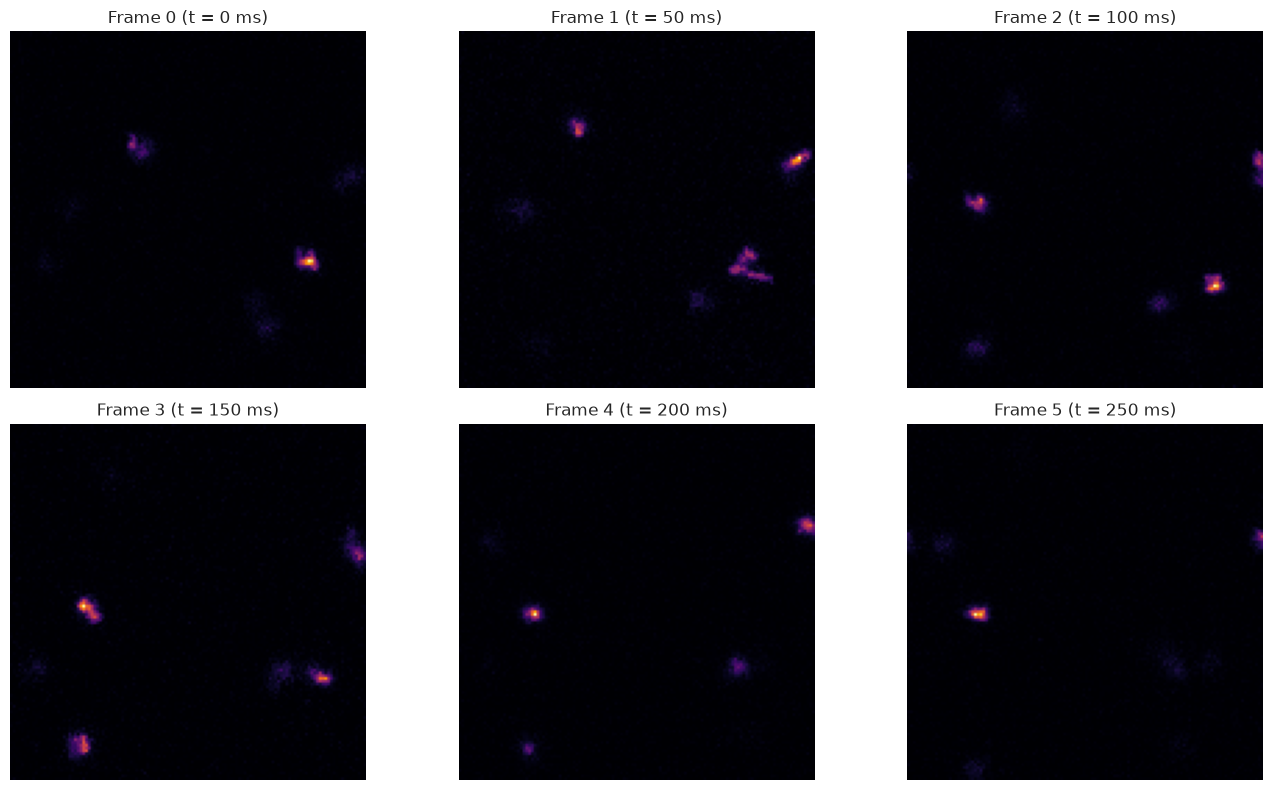

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(frames[i], cmap='inferno')
    ax.set_title(f'Frame {i} (t = {i*frame_time*1e3:.0f} ms)')
    ax.set_axis_off()
plt.tight_layout()
plt.savefig('lightsheet_sim_plots/fig3_camera_frames.png', dpi=150, bbox_inches='tight');

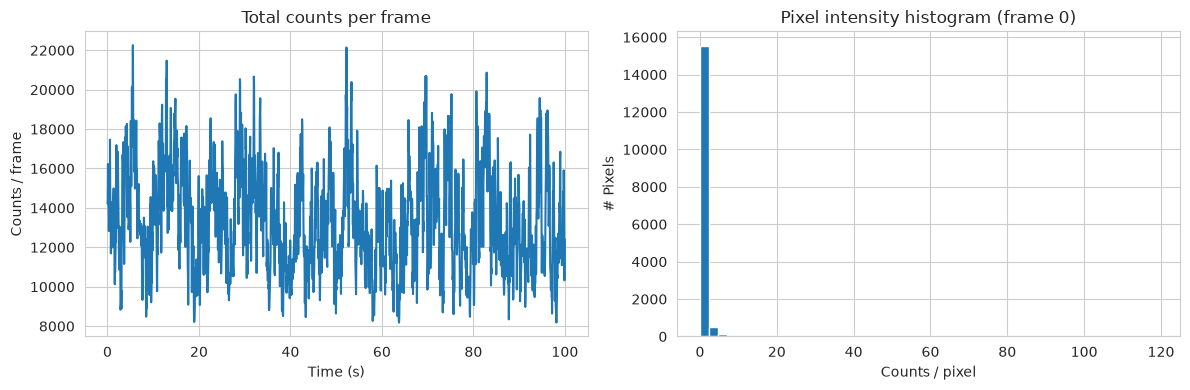

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t_frames = np.arange(frames.shape[0]) * frame_time
axes[0].plot(t_frames, frames.sum(axis=(1, 2)))
axes[0].set_xlabel('Time (s)'); axes[0].set_ylabel('Counts / frame')
axes[0].set_title('Total counts per frame')

f_max = frames[0].max()
axes[1].hist(frames[0].ravel(), bins=50, range=(0, f_max))
axes[1].set_xlabel('Counts / pixel'); axes[1].set_ylabel('# Pixels')
axes[1].set_title('Pixel intensity histogram (frame 0)')
plt.tight_layout()
plt.savefig('lightsheet_sim_plots/fig4_intensity_stats.png', dpi=150, bbox_inches='tight');

## 6. Observation-time statistics per molecule

A molecule is only visible while it is inside the light sheet. Each contiguous stretch with excitation weight $> 1/e^2$ (i.e. $|z| < w_0$) is one **sheet crossing**. Most crossings are grazing passes at the sheet edge that collect only tens of photons; a crossing is counted as **detectable** when it collects at least 100 photons in total (well above the background of the 128 × 128 ROI).

The statistics below quantify the average observation time per molecule and how many camera frames a molecule appears in — the diffusion-limited "burst length" of the light-sheet experiment.

In [12]:
# --- Observation-time statistics from the simulated trajectories ---
z = positions[:, 2, :]                      # (num_particles, n_samples)
w = ls_psf.excitation_weights(z)            # sheet excitation at each step
rate = w * em_rate                          # photons/s per particle per step
on = w > 1/np.e**2                          # inside the sheet (|z| < w0)

durs, photons = [], []
for i in range(z.shape[0]):
    d = np.diff(np.concatenate(([0], on[i].astype(int), [0])))
    starts = np.where(d == 1)[0]; ends = np.where(d == -1)[0]
    for s0, s1 in zip(starts, ends):
        durs.append((s1 - s0) * t_step)
        photons.append(rate[i, s0:s1].sum() * t_step)
durs = np.array(durs); photons = np.array(photons)
detectable = photons >= 100

print(f'Sheet crossings (excitation > 1/e^2): {len(durs)}')
print(f'  duration: mean {durs.mean()*1e3:.1f} ms, median {np.median(durs)*1e3:.1f} ms, P90 {np.percentile(durs, 90)*1e3:.0f} ms')
print(f'  photons per crossing: mean {photons.mean():.0f}, median {np.median(photons):.0f}')
print(f'Detectable crossings (>= 100 photons): {detectable.sum()} ({detectable.mean()*100:.0f}% of all crossings)')
print(f'  observation time: mean {durs[detectable].mean()*1e3:.0f} ms, median {np.median(durs[detectable])*1e3:.0f} ms, max {durs[detectable].max()*1e3:.0f} ms')
frames_appeared = np.ceil(durs[detectable] / frame_time + 0.5).astype(int)
print(f'  camera frames appeared in (t_frame = {frame_time*1e3:.0f} ms): mean {frames_appeared.mean():.2f}, median {np.median(frames_appeared):.0f}, P90 {np.percentile(frames_appeared, 90):.0f}')
print(f'  photons: mean {photons[detectable].mean():.0f}, median {np.median(photons[detectable]):.0f}')
print(f'Fraction of particle-time inside the sheet: {on.mean():.3f}')
# --- Scaling estimate for the 20% glycerol sample ---
# Diffusion times scale as 1/D: with eta(20% glycerol)/eta(water) = 1.8,
# D drops by 1.8x and observation times lengthen by the same factor.
viscosity_ratio = 1.8
print(f'\n20% glycerol scaling estimate (D -> D/{viscosity_ratio}):')
print(f'  mean observation time (detectable): {durs[detectable].mean()*1e3:.0f} ms -> {durs[detectable].mean()*1e3*viscosity_ratio:.0f} ms')
print(f'  median observation time (detectable): {np.median(durs[detectable])*1e3:.0f} ms -> {np.median(durs[detectable])*1e3*viscosity_ratio:.0f} ms')
print(f'  mean frames per molecule: {frames_appeared.mean():.2f} -> {frames_appeared.mean()*viscosity_ratio:.2f}')
print('  (refractive-index mismatch additionally broadens/dims the spots, see section 3)')

Sheet crossings (excitation > 1/e^2): 9751
  duration: mean 34.5 ms, median 4.0 ms, P90 94 ms
  photons per crossing: mean 1037, median 30
Detectable crossings (>= 100 photons): 3043 (31% of all crossings)
  observation time: mean 104 ms, median 41 ms, max 1365 ms
  camera frames appeared in (t_frame = 50 ms): mean 3.01, median 2, P90 7
  photons: mean 3270, median 705
Fraction of particle-time inside the sheet: 0.224

20% glycerol scaling estimate (D -> D/1.8):
  mean observation time (detectable): 104 ms -> 188 ms
  median observation time (detectable): 41 ms -> 74 ms
  mean frames per molecule: 3.01 -> 5.42
  (refractive-index mismatch additionally broadens/dims the spots, see section 3)


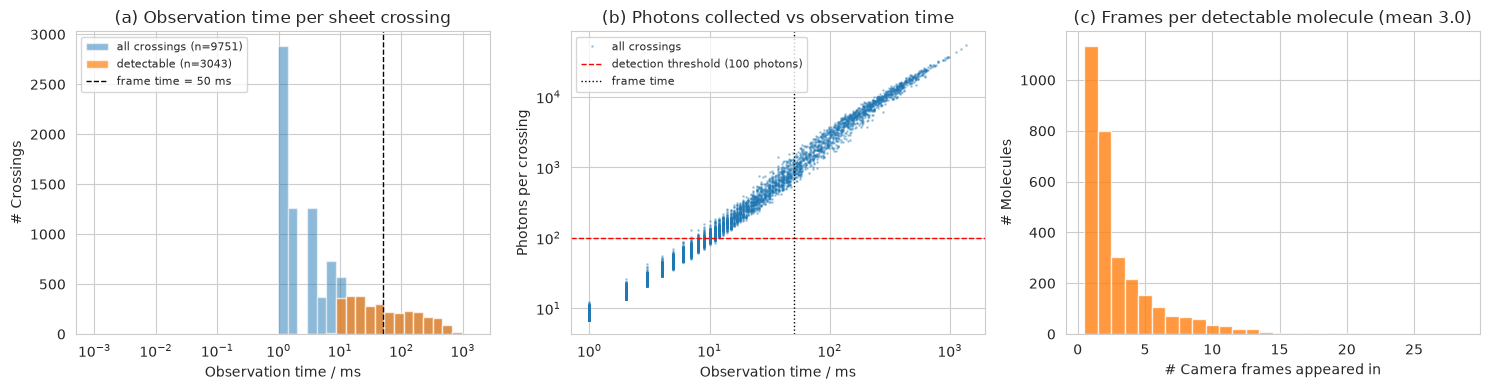

In [13]:
import os
os.makedirs('lightsheet_sim_plots', exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (a) crossing-duration histogram (log bins), all vs detectable
bins = np.logspace(np.log10(max(t_step, 1e-3)), np.log10(durs.max() * 1e3), 40)
axes[0].hist(durs * 1e3, bins=bins, alpha=0.5, label=f'all crossings (n={len(durs)})')
axes[0].hist(durs[detectable] * 1e3, bins=bins, alpha=0.7, label=f'detectable (n={detectable.sum()})')
axes[0].axvline(frame_time * 1e3, color='k', ls='--', lw=1, label=f'frame time = {frame_time*1e3:.0f} ms')
axes[0].set_xscale('log')
axes[0].set_xlabel('Observation time / ms'); axes[0].set_ylabel('# Crossings')
axes[0].set_title('(a) Observation time per sheet crossing')
axes[0].legend(fontsize=8)

# (b) photons vs duration, detectability threshold
axes[1].loglog(durs * 1e3, photons, '.', ms=2, alpha=0.3, label='all crossings')
axes[1].axhline(100, color='r', lw=1, ls='--', label='detection threshold (100 photons)')
axes[1].axvline(frame_time * 1e3, color='k', lw=1, ls=':', label='frame time')
axes[1].set_xlabel('Observation time / ms'); axes[1].set_ylabel('Photons per crossing')
axes[1].set_title('(b) Photons collected vs observation time')
axes[1].legend(fontsize=8)

# (c) distribution of camera frames per detectable molecule
maxf = frames_appeared.max()
axes[2].hist(frames_appeared, bins=np.arange(0.5, maxf + 1.5), color='C1', alpha=0.8)
axes[2].set_xlabel('# Camera frames appeared in'); axes[2].set_ylabel('# Molecules')
axes[2].set_title(f'(c) Frames per detectable molecule (mean {frames_appeared.mean():.1f})')
plt.tight_layout()
plt.savefig('lightsheet_sim_plots/fig5_observation_time_stats.png', dpi=150, bbox_inches='tight');

## 7. Save the camera frames

The frame stack is saved as HDF5 with the acquisition parameters as attributes. The pybromo trajectory file already contains the light-sheet PSF (via `LightSheetPSF.to_hdf5`), so the simulation is fully traceable.


In [14]:
sim_name = S.compact_name()
S.store.close()

filename = f'lightsheet_camera_{sim_name}.hdf5'
with tables.open_file(filename, 'w') as f:
    f.create_array('/', 'frames', obj=frames,
                   title='Simulated light-sheet camera frames (uint16)')
    for attr, value in [('frame_time', frame_time),
                        ('t_step', t_step),
                        ('pixel_size_m', pixel_size),
                        ('em_rate', em_rate),
                        ('background_rate', background_rate),
                        ('psf_hash', ls_psf.hash())]:
        f.set_node_attr(f.root, attr, value)
print('Saved:', filename)

Saved: lightsheet_camera_0d6b2b_P15_D1e-11_2pM_step1000.0us_t_max100.0s_ID0-0.hdf5


## Summary

- `lightsheet_psf.py` provides `LightSheetPSF`, a pybromo-compatible light-sheet PSF: a Gaussian excitation sheet ($w_0 = \lambda_{ex}/(\pi\,\mathrm{NA}_{sheet})$) multiplied by the `psfmodels` vectorial widefield detection PSF evaluated on a z stack.
- The pybromo particle simulation runs with camera parameters: **100 s duration, 1 ms step, 50 ms frame integration** (2000 frames of 128 × 128 pixels).
- `LightSheetPSF.render_camera_frames` bins the particle emission on the camera grid per z plane, convolves with the defocus-dependent detection kernel (photon-conserving), and Poisson-samples the result into uint16 camera frames.
- Validation: in-focus detection FWHM matches the Airy limit, the effective PSF is axially confined by the sheet Gaussian, photon counts are conserved at every defocus, and camera spots broaden away from focus.- Observation-time statistics: a molecule is detectable for ~100 ms on average (median ~40 ms, i.e. 2–3 camera frames), limited by diffusion out of the ~2 µm-thick sheet; all durations scale as $1/D$ when the diffusion coefficient is changed.
- 20 % glycerol: viscosity 1.8x -> diffusion times (incl. observation time) lengthen 1.8x (mean detectable observation ~190 ms); the refractive-index mismatch (1.333 -> 1.359 with a water objective) broadens the in-focus detection PSF laterally (0.35 -> 0.45 um FWHM) and axially (1.75 -> 2.00 um), doubles the axial asymmetry and cuts the Strehl-like peak ratio to ~0.44 (spherical aberration).
